In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Epoch 0/99
----------
train Loss: 0.9996 Acc: 0.6443
test Loss: 31.8982 Acc: 0.3007
Epoch 1/99
----------
train Loss: 0.7418 Acc: 0.7410
test Loss: 6.2360 Acc: 0.5145
Epoch 2/99
----------
train Loss: 0.5095 Acc: 0.8190
test Loss: 2.7181 Acc: 0.4022
Epoch 3/99
----------
train Loss: 0.5405 Acc: 0.8284
test Loss: 0.7973 Acc: 0.7283
Epoch 4/99
----------
train Loss: 0.4395 Acc: 0.8627
test Loss: 1.1171 Acc: 0.7029
Epoch 5/99
----------
train Loss: 0.3633 Acc: 0.8955
test Loss: 1.3537 Acc: 0.7464
Epoch 6/99
----------
train Loss: 0.3503 Acc: 0.8814
test Loss: 1.2850 Acc: 0.6812
Epoch 7/99
----------
train Loss: 0.3284 Acc: 0.8799
test Loss: 0.9824 Acc: 0.7428
Epoch 8/99
----------
train Loss: 0.3623 Acc: 0.8580
test Loss: 1.8746 Acc: 0.6558
Epoch 9/99
----------
train Loss: 0.3327 Acc: 0.8939
test Loss: 0.5540 Acc: 0.8043
Epoch 10/99
----------
train Loss: 0.2216 Acc: 0.9282
test Loss: 0.7322 Acc: 0.7790
Epoch 11/99
----------
train Loss: 0.2078 Acc: 0.9204
test Loss: 0.8830 Acc: 0.7681
E

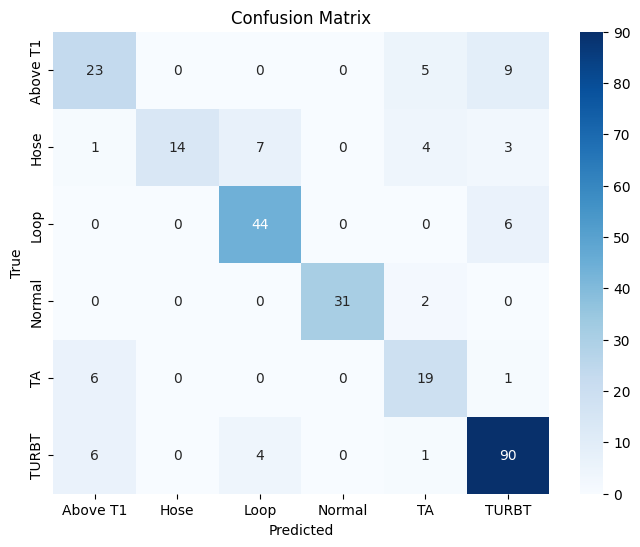

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Define Dataset Path and Hyperparameters
data_dir = '/content/drive/MyDrive/Bladder_Cancer/SAVE/SAVE'
num_classes = 6
batch_size = 32
num_epochs = 100
learning_rate = 0.001
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Image Transforms
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# 3. Load Dataset
image_datasets = {x: datasets.ImageFolder(root=f'{data_dir}/{x}', transform=data_transforms[x])
                  for x in ['train', 'test']}

dataloaders = {x: DataLoader(image_datasets[x], batch_size=batch_size, shuffle=True)
               for x in ['train', 'test']}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}
class_names = image_datasets['train'].classes

# 4. Load Pretrained ResNet-34 Model and Modify for Classification
model = models.resnet34(pretrained=True)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)  # Modify final layer for 6 classes
model = model.to(device)

# 5. Define Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# 6. Training Loop
def train_model(model, dataloaders, criterion, optimizer, num_epochs=25):
    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

    return model

model = train_model(model, dataloaders, criterion, optimizer, num_epochs)

# 7. Evaluation and Confusion Matrix
def evaluate_model(model, dataloaders):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    return all_labels, all_preds

labels, preds = evaluate_model(model, dataloaders)

# Classification Report
print("Classification Report:")
print(classification_report(labels, preds, target_names=class_names))

# Confusion Matrix
conf_matrix = confusion_matrix(labels, preds)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
